In [1]:

import pandas as pd
from sqlalchemy import create_engine, URL, text
from getpass import getpass

# MySQL credentials
username = input("root ")
password = getpass("JaiMata@21 ")

# Database connection
connection_url = URL.create(
    drivername="mysql+mysqlconnector",
    username=username,
    password=password,
    host="localhost",
    port=3306,
    database="Blinkitdb"
)

engine = create_engine(connection_url)

# Test connection
try:
    with engine.connect() as connection:

        database = connection.execute(
            text("SELECT DATABASE()")
        ).scalar()

        print("Connection successful!")
        print("Connected database:", database)

        tables = pd.read_sql(
            text("SHOW FULL TABLES"),
            connection
        )

        print("\nAvailable database objects:")
        print(tables)

except Exception as error:
    print("Connection failed:", error)


Connection failed: (mysql.connector.errors.ProgrammingError) 1045 (28000): Access denied for user 'root'@'localhost' (using password: NO)
(Background on this error at: https://sqlalche.me/e/21/f405)


In [2]:

from sqlalchemy import create_engine, URL, text
from getpass import getpass

username = "root"
password = getpass("Enter your MySQL root password: ")

connection_url = URL.create(
    "mysql+mysqlconnector",
    username=username,
    password=password,
    host="localhost",
    port=3306,
    database="Blinkitdb"
)

# Replace the old engine
engine = create_engine(connection_url, pool_pre_ping=True)

# Test connection
with engine.connect() as connection:
    print("Connected successfully!")
    print("Database:", connection.execute(
        text("SELECT DATABASE()")
    ).scalar())


ProgrammingError: (mysql.connector.errors.ProgrammingError) 1045 (28000): Access denied for user 'root'@'localhost' (using password: NO)
(Background on this error at: https://sqlalche.me/e/21/f405)

In [ ]:
import pandas as pd

df = pd.read_sql(
    "SELECT * FROM vw_blinkit_master",
    engine
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (662, 23)


,order_id,order_date,order_hour,order_day,customer_id,customer_segment,area,pincode,product_id,product_name,...,quantity,unit_price,line_revenue,delivery_variance_mins,sla_status,delivery_status,reasons_if_delayed,rating,sentiment,feedback_category
0,60465,2024-10-23 05:23:29,5,Wednesday,15808945,New,Gangtok,890545,361361,Unknown Product (361361),...,2,826.21,1652.42,5.0,Delayed,On Time,Traffic,4,Neutral,Product Quality
1,2237858,2023-04-02 03:45:11,3,Sunday,48281892,New,Vellore,691199,585299,Unknown Product (585299),...,1,799.46,799.46,3.0,Delayed,On Time,Traffic,3,Neutral,Delivery
2,3101265,2024-05-23 03:21:47,3,Thursday,89617089,New,Bidhannagar,710095,300159,Unknown Product (300159),...,1,44.35,44.35,3.0,Delayed,On Time,Traffic,1,Negative,Customer Service
3,5120698,2023-06-09 12:10:20,12,Friday,44174426,New,Salem,133683,187399,Unknown Product (187399),...,1,53.49,53.49,15.0,Delayed,Slightly Delayed,Traffic,5,Positive,Delivery
4,7550508,2023-10-20 10:54:27,10,Friday,93127511,Inactive,Bijapur,850740,140154,Unknown Product (140154),...,2,171.20,342.40,-1.0,Early Delivery,On Time,No Delay,5,Positive,Delivery


In [ ]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

Dataset shape: (662, 23)

Column names:
['order_id', 'order_date', 'order_hour', 'order_day', 'customer_id', 'customer_segment', 'area', 'pincode', 'product_id', 'product_name', 'category', 'brand', 'product_match_status', 'quantity', 'unit_price', 'line_revenue', 'delivery_variance_mins', 'sla_status', 'delivery_status', 'reasons_if_delayed', 'rating', 'sentiment', 'feedback_category']

Duplicate rows: 0

Missing values:


order_id                  0
order_date                0
order_hour                0
order_day                 0
customer_id               0
customer_segment          0
area                      0
pincode                   0
product_id                0
product_name              0
category                  0
brand                     0
product_match_status      0
quantity                  0
unit_price                0
line_revenue              0
delivery_variance_mins    0
sla_status                0
delivery_status           0
reasons_if_delayed        0
rating                    0
sentiment                 0
feedback_category         0
dtype: int64

#### These metrics establish the business baseline before we investigate customer behaviour, delivery performance, demand patterns and predictive modelling.

In [ ]:
# Overall business performance

print("Total Revenue:", round(df['line_revenue'].sum(), 2))
print("Total Orders:", df['order_id'].nunique())
print("Total Customers:", df['customer_id'].nunique())
print("Total Products:", df['product_id'].nunique())
print("Total Units Sold:", df['quantity'].sum())

print("Average Order Value:",
      round(df.groupby('order_id')['line_revenue'].sum().mean(), 2))

print("Average Selling Price:",
      round(df['unit_price'].mean(), 2))

# dataset contains 659 orders, 590 customers and ₹6.36 lakh revenue.

Total Revenue: 635752.18
Total Orders: 659
Total Customers: 590
Total Products: 245
Total Units Sold: 1309
Average Order Value: 964.72
Average Selling Price: 485.33


### Identify repeat customers, high-value customers and customer purchasing patterns.

In [ ]:
# Customer purchase behaviour

customer_analysis = (
    df.groupby('customer_id')
    .agg(
        total_orders=('order_id', 'nunique'),
        total_spent=('line_revenue', 'sum'),
        total_quantity=('quantity', 'sum')
    )
    .reset_index()
)

print("Repeat Customers:",
      (customer_analysis['total_orders'] > 1).sum())

print("One-time Customers:",
      (customer_analysis['total_orders'] == 1).sum())

print("Average Customer Spending:",
      round(customer_analysis['total_spent'].mean(), 2))

print("\nTop 10 Customers by Spending:")

display(
    customer_analysis
    .sort_values('total_spent', ascending=False)
    .head(10)
)

Repeat Customers: 67
One-time Customers: 523
Average Customer Spending: 1077.55

Top 10 Customers by Spending:


,customer_id,total_orders,total_spent,total_quantity
386,67538982,3,5197.03,7
145,24153726,2,5130.33,6
224,39042103,2,4674.75,5
433,74682740,2,4582.44,6
401,69863493,2,4210.94,5
311,54619715,2,3992.36,5
579,98225598,2,3805.44,6
180,30188374,2,3681.70,4
90,13465850,2,3558.81,6
39,6579892,2,3551.39,5


In [ ]:
## top customer has: 3 orders, ₹5,197.03 total spending,7 units purchased


#### Customer segmentation
 classify customers into spending groups.

In [ ]:
customer_analysis['customer_segment'] = pd.qcut(
    customer_analysis['total_spent'].rank(method='first'),
    q=4,
    labels=['Low Value', 'Regular', 'High Value', 'VIP']
)

display(
    customer_analysis.groupby(
        'customer_segment', observed=False
    ).agg(
        customers=('customer_id', 'count'),
        average_spending=('total_spent', 'mean'),
        total_revenue=('total_spent', 'sum')
    ).round(2)
)

,customers,average_spending,total_revenue
customer_segment,,,
Low Value,148,206.87,30616.54
Regular,147,605.94,89073.27
High Value,147,1123.22,165113.85
VIP,148,2371.27,350948.52


In [ ]:
## Important findings:
#- VIP customers contribute approximately 55.2% of total revenue.
#- Low Value customers contribute only 4.8%.
#- VIP customers are a high-priority retention group.

#### Product category performance
which product categories generate the most revenue

In [ ]:
category_analysis = (
    df.groupby('category')
    .agg(
        total_revenue=('line_revenue', 'sum'),
        total_quantity=('quantity', 'sum'),
        total_orders=('order_id', 'nunique')
    )
    .sort_values('total_revenue', ascending=False)
    .round(2)
)

display(category_analysis)

,total_revenue,total_quantity,total_orders
category,,,
Uncategorized,397140.18,826,424
Pharmacy,58110.42,85,40
Dairy & breakfast,44261.46,71,34
Fruits & vegetables,32522.57,60,30
Cold drinks & juices,23713.81,43,22
Pet care,15647.23,44,21
Instant & frozen food,13155.31,36,22
Snacks & munchies,12510.12,36,18
Baby care,11969.96,29,13


Uncategorized generates ₹3,90,958.55 — approximately 61.5% of total revenue.



Pharmacy is the highest-revenue identified category at ₹58,110.42.



Dairy & breakfast follows at ₹44,261.46.



Two category values are actually timestamps, not product categories.

#### the category issue

In [ ]:
# Exclude unknown categories
valid_categories = df[
    ~df['category'].isin(['Uncategorized', 'Unknown', ''])
].copy()

category_analysis = (
    valid_categories.groupby('category')
    .agg(
        total_revenue=('line_revenue', 'sum'),
        total_quantity=('quantity', 'sum'),
        total_orders=('order_id', 'nunique')
    )
    .sort_values('total_revenue', ascending=False)
    .round(2)
)

display(category_analysis)


,total_revenue,total_quantity,total_orders
category,,,
Pharmacy,58110.42,85,40
Dairy & breakfast,44261.46,71,34
Fruits & vegetables,32522.57,60,30
Cold drinks & juices,23713.81,43,22
Pet care,15647.23,44,21
Instant & frozen food,13155.31,36,22
Snacks & munchies,12510.12,36,18
Baby care,11969.96,29,13
Grocery & staples,9434.16,39,14


In [ ]:
delivery_analysis = df.groupby(
    ['sla_status', 'delivery_status'],
    dropna=False
).agg(
    total_orders=('order_id', 'nunique'),
    avg_delivery_variance=('delivery_variance_mins', 'mean'),
    total_revenue=('line_revenue', 'sum')
).round(2)

display(delivery_analysis)

total_orders  avg_delivery_variance  \
sla_status     delivery_status                                              
Delayed        On Time                         213                   3.07   
               Significantly Delayed            63                  22.16   
               Slightly Delayed                136                  10.68   
Early Delivery On Time                         215                  -2.95   
Exact On-Time  On Time                          32                   0.00   

                                      total_revenue  
sla_status     delivery_status                       
Delayed        On Time                    206372.91  
               Significantly Delayed       68112.56  
               Slightly Delayed           138443.81  
Early Delivery On Time                    190179.22  
Exact On-Time  On Time                     32643.68

In [ ]:
order_df = (
    df.groupby('order_id')
    .agg(
        order_date=('order_date', 'first'),
        order_hour=('order_hour', 'first'),
        order_day=('order_day', 'first'),
        customer_id=('customer_id', 'first'),
        customer_segment=('customer_segment', 'first'),
        area=('area', 'first'),

        total_quantity=('quantity', 'sum'),
        total_revenue=('line_revenue', 'sum'),
        avg_unit_price=('unit_price', 'mean'),
        total_items=('product_id', 'size'),
        unique_products=('product_id', 'nunique'),

        delivery_variance_mins=('delivery_variance_mins', 'first'),
        sla_status=('sla_status', 'first'),
        delivery_status=('delivery_status', 'first'),

        rating=('rating', 'first'),
        sentiment=('sentiment', 'first')
    )
    .reset_index()
)

print("Order-level dataset shape:", order_df.shape)
print("Unique orders:", order_df['order_id'].nunique())

display(order_df.head())

Order-level dataset shape: (659, 17)
Unique orders: 659


,order_id,order_date,order_hour,order_day,customer_id,customer_segment,area,total_quantity,total_revenue,avg_unit_price,total_items,unique_products,delivery_variance_mins,sla_status,delivery_status,rating,sentiment
0,60465,2024-10-23 05:23:29,5,Wednesday,15808945,New,Gangtok,2,1652.42,826.21,1,1,5.0,Delayed,On Time,4,Neutral
1,2237858,2023-04-02 03:45:11,3,Sunday,48281892,New,Vellore,1,799.46,799.46,1,1,3.0,Delayed,On Time,3,Neutral
2,3101265,2024-05-23 03:21:47,3,Thursday,89617089,New,Bidhannagar,1,44.35,44.35,1,1,3.0,Delayed,On Time,1,Negative
3,5120698,2023-06-09 12:10:20,12,Friday,44174426,New,Salem,1,53.49,53.49,1,1,15.0,Delayed,Slightly Delayed,5,Positive
4,7550508,2023-10-20 10:54:27,10,Friday,93127511,Inactive,Bijapur,2,342.40,171.20,1,1,-1.0,Early Delivery,On Time,5,Positive


In [ ]:
#Validate delivery prediction labels

print("SLA Status:")
display(order_df['sla_status'].value_counts(dropna=False))

print("Delivery Status:")
display(order_df['delivery_status'].value_counts(dropna=False))

print("SLA vs Delivery Status:")
display(pd.crosstab(
    order_df['sla_status'],
    order_df['delivery_status'],
    dropna=False
))

SLA Status:


sla_status
Delayed           412
Early Delivery    215
Exact On-Time      32
Name: count, dtype: int64

Delivery Status:


delivery_status
On Time                  460
Slightly Delayed         136
Significantly Delayed     63
Name: count, dtype: int64

SLA vs Delivery Status:


delivery_status,On Time,Significantly Delayed,Slightly Delayed
sla_status,,,
Delayed,213,63,136
Early Delivery,215,0,0
Exact On-Time,32,0,0


sla_status: 412 Delayed, 215 Early Delivery, 32 Exact On-Time.



delivery_status: 460 On Time, 136 Slightly Delayed, 63 Significantly Delayed.


In [ ]:
display(
    order_df.groupby('sla_status')['delivery_variance_mins']
    .agg(['count', 'min', 'max', 'mean', 'median'])
    .round(2)
)

,count,min,max,mean,median
sla_status,,,,,
Delayed,412,1.0,30.0,8.50,5.0
Early Delivery,215,-5.0,-1.0,-2.95,-3.0
Exact On-Time,32,0.0,0.0,0.00,0.0


In [ ]:

order_df['delivery_target'] = order_df['delivery_status'].map({
    'On Time': 0,
    'Slightly Delayed': 1,
    'Significantly Delayed': 2
})

display(order_df['delivery_target'].value_counts())

delivery_target
0    460
1    136
2     63
Name: count, dtype: int64

In [ ]:
import seaborn as sns

In [ ]:
delivery_features = [
    'order_hour',
    'order_day',
    'customer_segment',
    'area',
    'total_quantity',
    'total_items',
    'unique_products',
    'total_revenue',
    'avg_unit_price'
]

X_delivery = order_df[delivery_features].copy()
y_delivery = order_df['delivery_target'].copy()

print("Feature shape:", X_delivery.shape)
print("Target shape:", y_delivery.shape)

display(X_delivery.head())

Feature shape: (659, 9)
Target shape: (659,)


,order_hour,order_day,customer_segment,area,total_quantity,total_items,unique_products,total_revenue,avg_unit_price
0,5,Wednesday,New,Gangtok,2,1,1,1652.42,826.21
1,3,Sunday,New,Vellore,1,1,1,799.46,799.46
2,3,Thursday,New,Bidhannagar,1,1,1,44.35,44.35
3,12,Friday,New,Salem,1,1,1,53.49,53.49
4,10,Friday,Inactive,Bijapur,2,1,1,342.40,171.20


In [ ]:
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    'order_hour',
    'total_quantity',
    'total_items',
    'unique_products',
    'total_revenue',
    'avg_unit_price'
]

categorical_features = [
    'order_day',
    'customer_segment',
    'area'
]

X_train, X_test, y_train, y_test = train_test_split(
    X_delivery,
    y_delivery,
    test_size=0.20,
    random_state=42,
    stratify=y_delivery
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training data: (527, 9)
Testing data: (132, 9)

Training target distribution:
delivery_target
0    368
1    109
2     50
Name: count, dtype: int64

Testing target distribution:
delivery_target
0    92
1    27
2    13
Name: count, dtype: int64


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(
        random_state=42, class_weight='balanced', max_depth=4
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, random_state=42, class_weight='balanced'
    ),
    'SVM': SVC(class_weight='balanced')
}

results = []

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Macro F1': f1_score(y_test, predictions, average='macro')
    })

    print(f'\n{name}')
    print(classification_report(
        y_test, predictions,
        labels=[0, 1, 2],
        zero_division=0
    ))

results_df = pd.DataFrame(results).sort_values(
    'Macro F1', ascending=False
)

display(results_df.round(3))


Logistic Regression
              precision    recall  f1-score   support

           0       0.69      0.60      0.64        92
           1       0.23      0.26      0.25        27
           2       0.05      0.08      0.06        13

    accuracy                           0.48       132
   macro avg       0.32      0.31      0.31       132
weighted avg       0.53      0.48      0.50       132


Decision Tree
              precision    recall  f1-score   support

           0       0.73      0.36      0.48        92
           1       0.22      0.52      0.30        27
           2       0.09      0.15      0.11        13

    accuracy                           0.37       132
   macro avg       0.35      0.34      0.30       132
weighted avg       0.56      0.37      0.41       132


Random Forest
              precision    recall  f1-score   support

           0       0.69      0.99      0.82        92
           1       0.00      0.00      0.00        27
           2       0.00 

,Model,Accuracy,Macro F1
3,SVM,0.492,0.376
0,Logistic Regression,0.477,0.314
1,Decision Tree,0.371,0.300
2,Random Forest,0.689,0.272


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

svm_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', SVC(class_weight='balanced'))
])

svm_pipeline.fit(X_train, y_train)

svm_predictions = svm_pipeline.predict(X_test)

print(classification_report(
    y_test,
    svm_predictions,
    target_names=[
        'On Time',
        'Slightly Delayed',
        'Significantly Delayed'
    ],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, svm_predictions))

                       precision    recall  f1-score   support

              On Time       0.75      0.55      0.64        92
     Slightly Delayed       0.26      0.41      0.32        27
Significantly Delayed       0.14      0.23      0.17        13

             accuracy                           0.49       132
            macro avg       0.38      0.40      0.38       132
         weighted avg       0.59      0.49      0.53       132

Confusion Matrix:
[[51 27 14]
 [11 11  5]
 [ 6  4  3]]


In [ ]:
rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    ))
])

rf_pipeline.fit(X_train, y_train)

feature_names = (
    rf_pipeline.named_steps['preprocessor']
    .get_feature_names_out()
)

importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf_pipeline.named_steps['model'].feature_importances_
}).sort_values('Importance', ascending=False)

display(importance.head(15))

,Feature,Importance
5,num__avg_unit_price,0.116107
4,num__total_revenue,0.115983
0,num__order_hour,0.105266
1,num__total_quantity,0.041351
9,cat__order_day_Sunday,0.021133
16,cat__customer_segment_Regular,0.020226
15,cat__customer_segment_Premium,0.019736
14,cat__customer_segment_New,0.019428
13,cat__customer_segment_Inactive,0.019094
12,cat__order_day_Wednesday,0.016969


In [ ]:
df['order_date'] = pd.to_datetime(df['order_date'], errors='coerce')

reference_date = df['order_date'].max() + pd.Timedelta(days=1)

rfm = (
    df.groupby('customer_id')
    .agg(
        Recency=('order_date', lambda x: (reference_date - x.max()).days),
        Frequency=('order_id', 'nunique'),
        Monetary=('line_revenue', 'sum')
    )
    .reset_index()
)

rfm.head()

,customer_id,Recency,Frequency,Monetary
0,119099,501,1,891.60
1,188838,259,1,825.46
2,376144,197,1,709.82
3,469006,283,1,40.70
4,625395,213,2,2760.54


In [ ]:
rfm[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,590.000000,590.000000,590.000000
mean,286.722034,1.116949,1077.546068
std,174.364684,0.332022,894.985695
min,1.000000,1.000000,13.250000
25%,130.000000,1.000000,415.750000
50%,281.500000,1.000000,831.100000
75%,435.500000,1.000000,1636.470000
max,600.000000,3.000000,5197.030000


In [ ]:
from sklearn.preprocessing import StandardScaler

# Select RFM features
X = rfm[['Recency', 'Frequency', 'Monetary']].copy()

# Handle skewness
import numpy as np

X = np.log1p(X)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Scaled dataset shape:", X_scaled.shape)

Scaled dataset shape: (590, 3)


In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

inertia = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    inertia.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

# Plot both evaluation metrics
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_values, inertia, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_values, silhouette_scores, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

print("Silhouette scores:", dict(zip(k_values, silhouette_scores)))

NameError: name 'X_scaled' is not defined

In [ ]:
for k, inertia_value, silhouette_value in zip(
    k_values, inertia, silhouette_scores
):
    print(
        f"K={k} | Inertia={inertia_value:.2f} "
        f"| Silhouette={silhouette_value:.4f}"
    )

K=2 | Inertia=1104.97 | Silhouette=0.5664
K=3 | Inertia=767.68 | Silhouette=0.3723
K=4 | Inertia=504.89 | Silhouette=0.4377
K=5 | Inertia=420.73 | Silhouette=0.3932
K=6 | Inertia=337.97 | Silhouette=0.3944
K=7 | Inertia=289.12 | Silhouette=0.3956
K=8 | Inertia=248.51 | Silhouette=0.4037


In [ ]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['Cluster'] = kmeans.fit_predict(X_scaled)



Cluster
0    134
1     67
2    279
3    110
Name: count, dtype: int64


In [ ]:
print(rfm['Cluster'].value_counts().sort_index())

In [ ]:
cluster_profile = (
    rfm.groupby('Cluster')
    .agg(
        Customers=('customer_id', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean'),
        Total_Revenue=('Monetary', 'sum')
    )
    .round(2)
)

cluster_profile

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue
Cluster,,,,,
0,134,308.49,1.00,203.71,27297.68
1,67,181.60,2.03,2026.91,135803.16
2,279,386.55,1.00,1271.90,354859.29
3,110,71.03,1.00,1070.84,117792.05


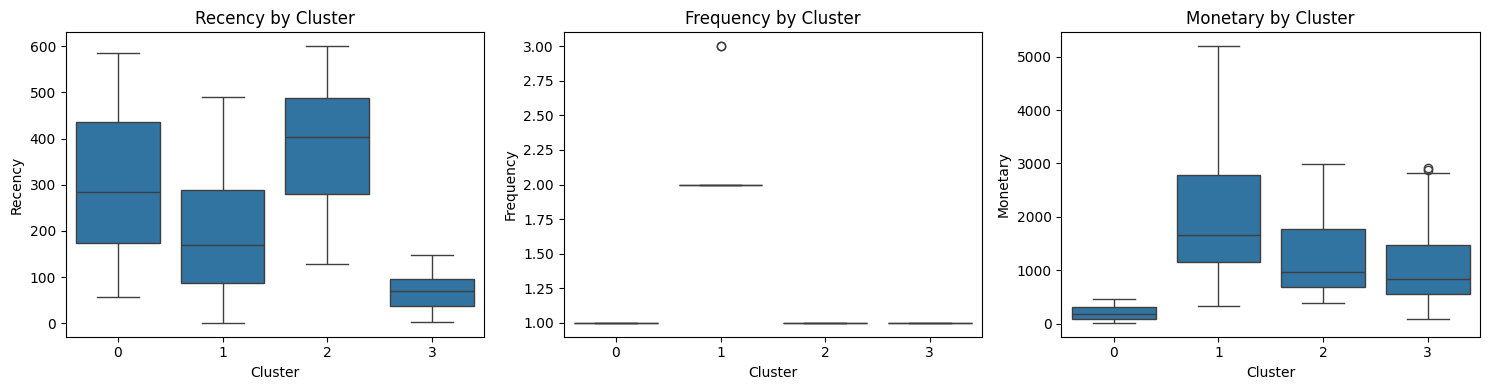

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(data=rfm, x='Cluster', y='Recency', ax=axes[0])
axes[0].set_title('Recency by Cluster')

sns.boxplot(data=rfm, x='Cluster', y='Frequency', ax=axes[1])
axes[1].set_title('Frequency by Cluster')

sns.boxplot(data=rfm, x='Cluster', y='Monetary', ax=axes[2])
axes[2].set_title('Monetary by Cluster')

plt.tight_layout()
plt.show()

In [ ]:
final_report = (
    rfm.groupby('Cluster')
    .agg(
        Customers=('customer_id', 'count'),
        Avg_Recency=('Recency', 'mean'),
        Avg_Frequency=('Frequency', 'mean'),
        Avg_Monetary=('Monetary', 'mean'),
        Revenue=('Monetary', 'sum')
    )
    .round(2)
)

final_report['Revenue_Share_%'] = (
    final_report['Revenue'] / rfm['Monetary'].sum() * 100
).round(2)

final_report

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Revenue,Revenue_Share_%
Cluster,,,,,,
0,134,308.49,1.00,203.71,27297.68,4.29
1,67,181.60,2.03,2026.91,135803.16,21.36
2,279,386.55,1.00,1271.90,354859.29,55.82
3,110,71.03,1.00,1070.84,117792.05,18.53


Cluster 2 contributes 55.82% of total customer revenue, while Cluster 1 has the highest average spending and is the only segment with average frequency above 1

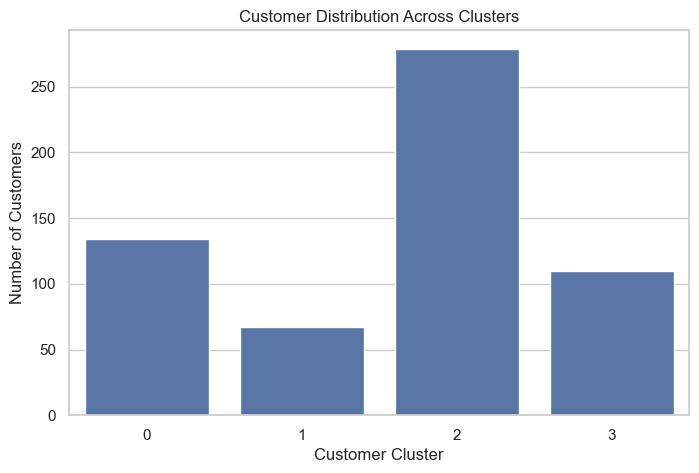

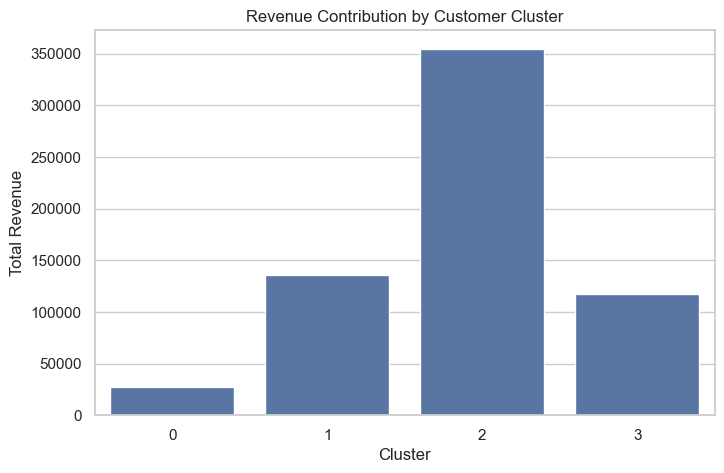

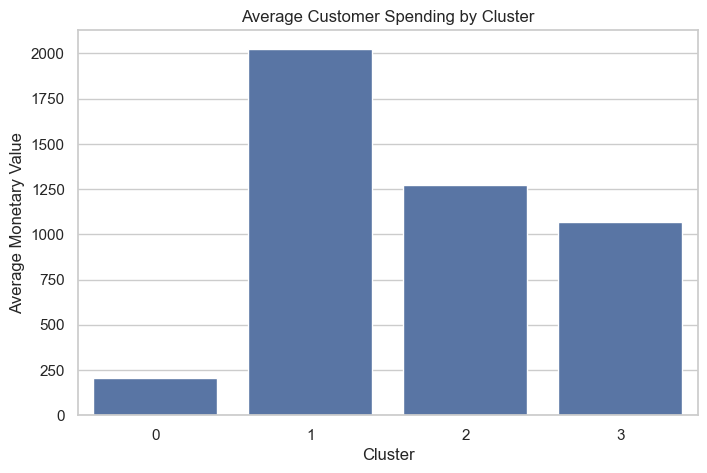

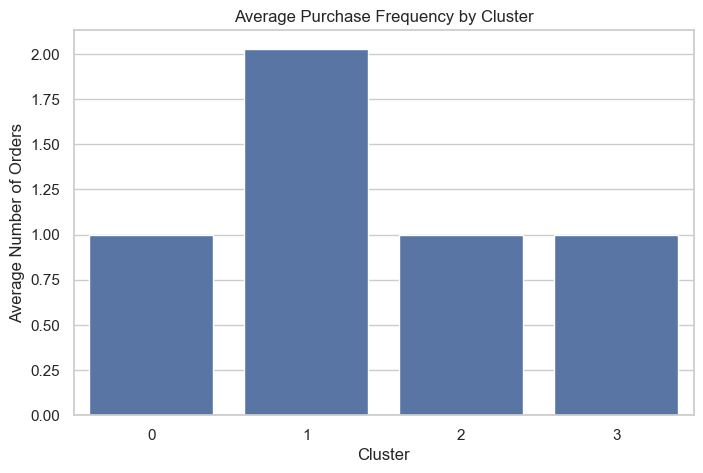

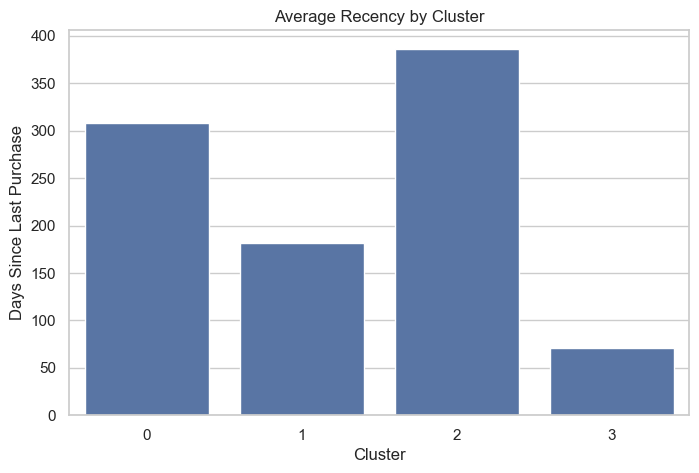

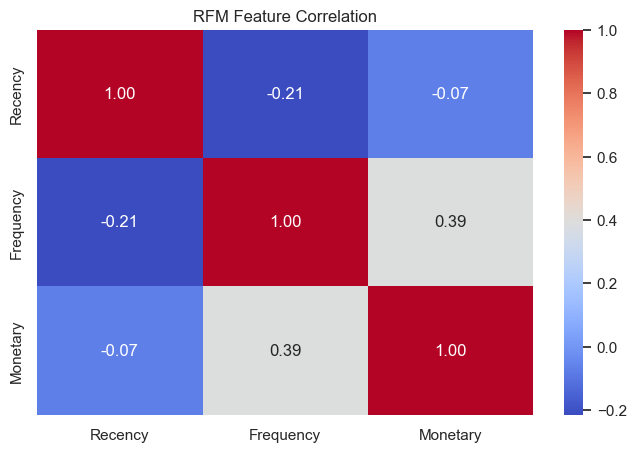

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Customer distribution across clusters
plt.figure(figsize=(8, 5))
sns.countplot(data=rfm, x='Cluster')
plt.title('Customer Distribution Across Clusters')
plt.xlabel('Customer Cluster')
plt.ylabel('Number of Customers')
plt.show()


# 2. Revenue contribution by cluster
plt.figure(figsize=(8, 5))
sns.barplot(data=final_report.reset_index(),
            x='Cluster', y='Revenue')
plt.title('Revenue Contribution by Customer Cluster')
plt.ylabel('Total Revenue')
plt.show()


# 3. Average spending by cluster
plt.figure(figsize=(8, 5))
sns.barplot(data=final_report.reset_index(),
            x='Cluster', y='Avg_Monetary')
plt.title('Average Customer Spending by Cluster')
plt.ylabel('Average Monetary Value')
plt.show()


# 4. Average purchase frequency
plt.figure(figsize=(8, 5))
sns.barplot(data=final_report.reset_index(),
            x='Cluster', y='Avg_Frequency')
plt.title('Average Purchase Frequency by Cluster')
plt.ylabel('Average Number of Orders')
plt.show()


# 5. Recency comparison
plt.figure(figsize=(8, 5))
sns.barplot(data=final_report.reset_index(),
            x='Cluster', y='Avg_Recency')
plt.title('Average Recency by Cluster')
plt.ylabel('Days Since Last Purchase')
plt.show()


# 6. RFM relationship heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    rfm[['Recency', 'Frequency', 'Monetary']].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title('RFM Feature Correlation')
plt.show()

In [ ]:
rfm.to_csv('blinkit_customer_segments.csv', index=False)

final_report.to_csv('blinkit_customer_segment_report.csv')

print("Customer segmentation reports saved successfully!")

Customer segmentation reports saved successfully!


In [ ]:
daily_demand = (
    df.groupby(df['order_date'].dt.date)
    .agg(
        Total_Orders=('order_id', 'nunique'),
        Total_Quantity=('quantity', 'sum'),
        Total_Revenue=('line_revenue', 'sum')
    )
    .reset_index()
)

daily_demand.rename(columns={'order_date': 'Date'}, inplace=True)
daily_demand['Date'] = pd.to_datetime(daily_demand['Date'])

print("Date range:", daily_demand['Date'].min(), "to", daily_demand['Date'].max())
print("Total days:", daily_demand['Date'].nunique())

daily_demand.head()

Date range: 2023-03-16 00:00:00 to 2024-11-04 00:00:00
Total days: 396


,Date,Total_Orders,Total_Quantity,Total_Revenue
0,2023-03-16,1,2,1726.36
1,2023-03-17,1,1,530.85
2,2023-03-19,1,2,166.36
3,2023-03-21,2,3,759.34
4,2023-03-22,1,1,491.39


In [ ]:
daily_demand = (
    daily_demand
    .set_index('Date')
    .asfreq('D')
    .fillna(0)
    .reset_index()
)

print("Total calendar days:", len(daily_demand))
print("Missing dates after filling:", daily_demand['Total_Quantity'].isna().sum())

Total calendar days: 600
Missing dates after filling: 0


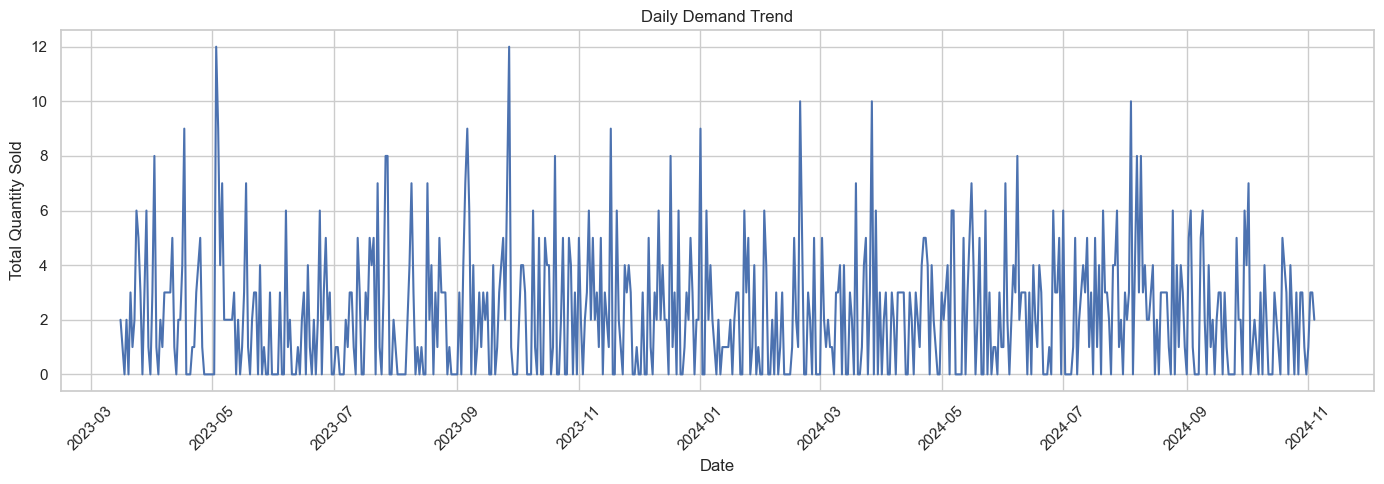

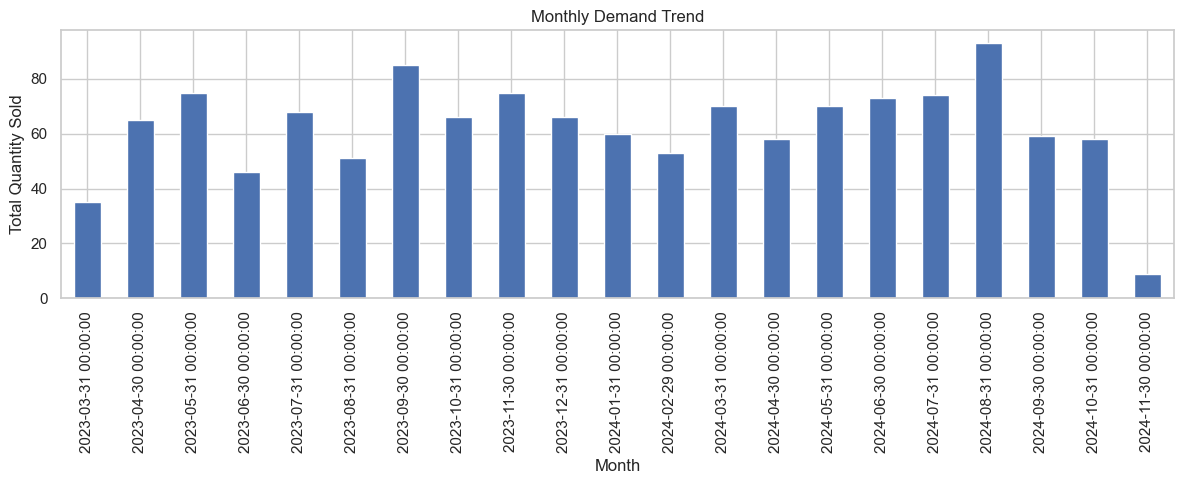

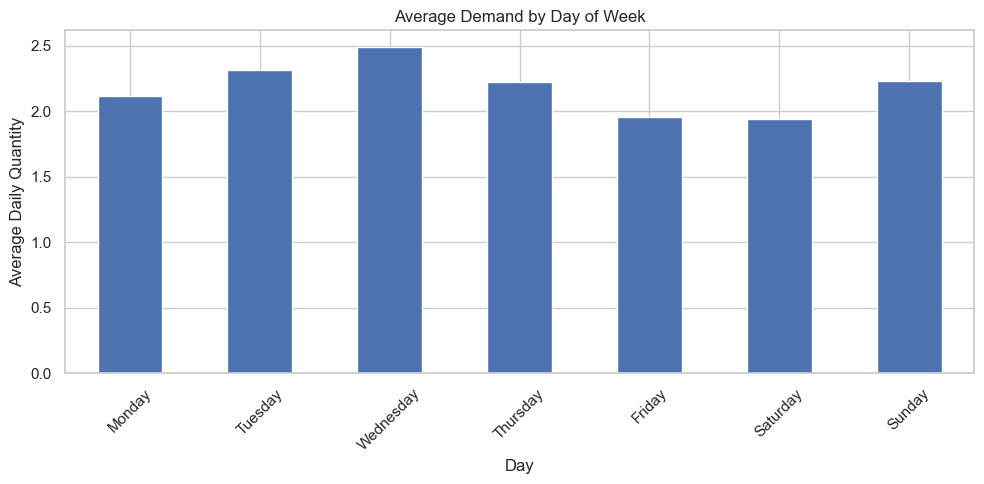

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(
    daily_demand['Date'],
    daily_demand['Total_Quantity']
)
plt.title('Daily Demand Trend')
plt.xlabel('Date')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Monthly demand
monthly_demand = (
    daily_demand
    .set_index('Date')['Total_Quantity']
    .resample('ME')
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_demand.plot(kind='bar')
plt.title('Monthly Demand Trend')
plt.xlabel('Month')
plt.ylabel('Total Quantity Sold')
plt.tight_layout()
plt.show()


# Day-of-week demand
daily_demand['Day_Name'] = daily_demand['Date'].dt.day_name()

weekday_demand = (
    daily_demand.groupby('Day_Name')['Total_Quantity']
    .mean()
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

weekday_demand.plot(kind='bar', figsize=(10, 5))
plt.title('Average Demand by Day of Week')
plt.xlabel('Day')
plt.ylabel('Average Daily Quantity')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Create time-based features
forecast_df = daily_demand[['Date', 'Total_Quantity']].copy()

forecast_df['Day_of_Week'] = forecast_df['Date'].dt.dayofweek
forecast_df['Month'] = forecast_df['Date'].dt.month
forecast_df['Day_of_Month'] = forecast_df['Date'].dt.day

# Lag features
forecast_df['Lag_1'] = forecast_df['Total_Quantity'].shift(1)
forecast_df['Lag_7'] = forecast_df['Total_Quantity'].shift(7)

# Rolling average using only previous days
forecast_df['Rolling_7'] = (
    forecast_df['Total_Quantity']
    .shift(1)
    .rolling(window=7)
    .mean()
)

forecast_df = forecast_df.dropna().reset_index(drop=True)

forecast_df.head()

,Date,Total_Quantity,Day_of_Week,Month,Day_of_Month,Lag_1,Lag_7,Rolling_7
0,2023-03-23,2.0,3,3,23,1.0,2.0,1.285714
1,2023-03-24,6.0,4,3,24,2.0,1.0,1.285714
2,2023-03-25,5.0,5,3,25,6.0,0.0,2.000000
3,2023-03-26,3.0,6,3,26,5.0,2.0,2.714286
4,2023-03-27,0.0,0,3,27,3.0,0.0,2.857143


In [ ]:
split_index = int(len(forecast_df) * 0.80)

train = forecast_df.iloc[:split_index].copy()
test = forecast_df.iloc[split_index:].copy()

features = [
    'Day_of_Week',
    'Month',
    'Day_of_Month',
    'Lag_1',
    'Lag_7',
    'Rolling_7'
]

X_train = train[features]
y_train = train['Total_Quantity']

X_test = test[features]
y_test = test['Total_Quantity']

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training period:", train['Date'].min(), "to", train['Date'].max())
print("Testing period:", test['Date'].min(), "to", test['Date'].max())

Training rows: 474
Testing rows: 119
Training period: 2023-03-23 00:00:00 to 2024-07-08 00:00:00
Testing period: 2024-07-09 00:00:00 to 2024-11-04 00:00:00


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=6,
        random_state=42
    )
}

results = []
predictions = {}

# Baseline: previous week's demand
predictions['Weekly Naive'] = test['Lag_7'].values

for name, model in models.items():
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    pred = np.maximum(pred, 0)

    predictions[name] = pred

# Evaluate all models
for name, pred in predictions.items():
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))

    results.append({
        'Model': name,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2)
    })

results_df = pd.DataFrame(results).sort_values('MAE')

results_df

,Model,MAE,RMSE
2,Random Forest,1.69,2.15
1,Linear Regression,1.71,2.14
0,Weekly Naive,2.51,3.16


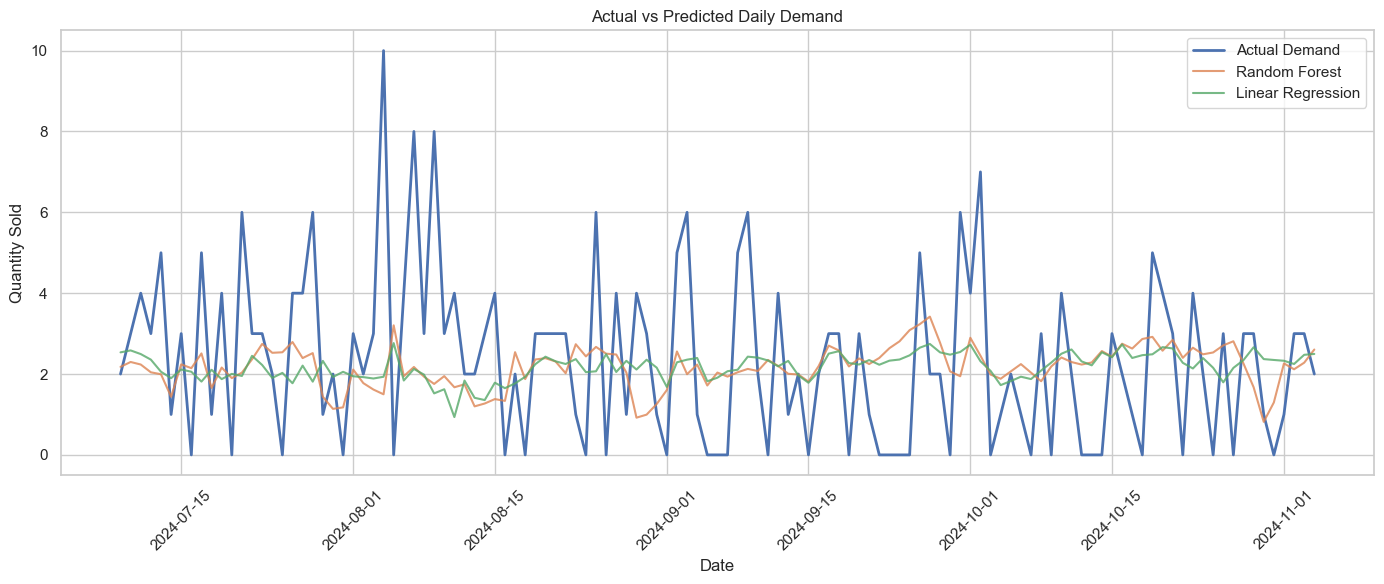

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    test['Date'],
    y_test.values,
    label='Actual Demand',
    linewidth=2
)

plt.plot(
    test['Date'],
    predictions['Random Forest'],
    label='Random Forest',
    alpha=0.8
)

plt.plot(
    test['Date'],
    predictions['Linear Regression'],
    label='Linear Regression',
    alpha=0.8
)

plt.title('Actual vs Predicted Daily Demand')
plt.xlabel('Date')
plt.ylabel('Quantity Sold')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import mean_absolute_percentage_error

for name in ['Random Forest', 'Linear Regression']:
    mape = mean_absolute_percentage_error(
        y_test,
        predictions[name]
    ) * 100

    print(f'{name} MAPE: {mape:.2f}%')

Random Forest MAPE: 268567281123385056.00%
Linear Regression MAPE: 262903990083434656.00%


In [ ]:
for name in ['Random Forest', 'Linear Regression']:
    wape = (
        np.sum(np.abs(y_test.values - predictions[name]))
        / np.sum(np.abs(y_test.values))
    ) * 100

    print(f'{name} WAPE: {wape:.2f}%')

Random Forest WAPE: 71.77%
Linear Regression WAPE: 72.45%


        Feature  Importance
5     Rolling_7    0.272380
2  Day_of_Month    0.263795
3         Lag_1    0.159013
1         Month    0.122044
4         Lag_7    0.102957
0   Day_of_Week    0.079811


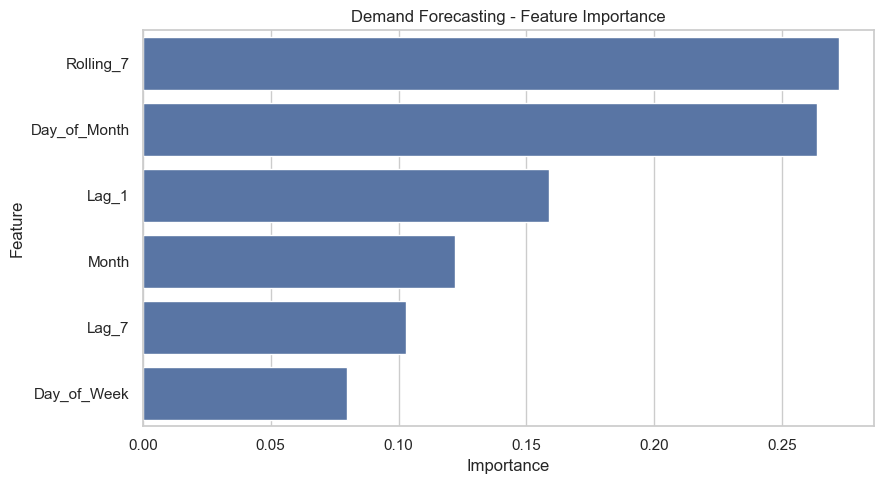

In [ ]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': models['Random Forest'].feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)
plt.title('Demand Forecasting - Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

Lag_1: Quantity sold on the previous day.



Lag_7: Quantity sold exactly 7 days earlier (the same weekday last week).



Rolling_7: Average quantity sold over the previous 7 days.

In [ ]:
feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': models['Random Forest'].feature_importances_
}).sort_values('Importance', ascending=False)

feature_importance

,Feature,Importance
5,Rolling_7,0.272380
2,Day_of_Month,0.263795
3,Lag_1,0.159013
1,Month,0.122044
4,Lag_7,0.102957
0,Day_of_Week,0.079811


In [ ]:
ml_summary = pd.DataFrame([
    {
        'Model': 'Delivery Prediction',
        'Algorithm': 'Random Forest',
        'Metric': 'Accuracy / Macro F1',
        'Score': '68.9% / 27.2%',
        'Result': 'Weak class-wise performance'
    },
    {
        'Model': 'Customer Segmentation',
        'Algorithm': 'K-Means',
        'Metric': 'Silhouette Score',
        'Score': '0.4377',
        'Result': '4 exploratory customer segments'
    },
    {
        'Model': 'Demand Forecasting',
        'Algorithm': 'Random Forest',
        'Metric': 'MAE / RMSE / WAPE',
        'Score': '1.69 / 2.15 / 71.77%',
        'Result': 'Limited forecasting accuracy'
    }
])

ml_summary

,Model,Algorithm,Metric,Score,Result
0,Delivery Prediction,Random Forest,Accuracy / Macro F1,68.9% / 27.2%,Weak class-wise performance
1,Customer Segmentation,K-Means,Silhouette Score,0.4377,4 exploratory customer segments
2,Demand Forecasting,Random Forest,MAE / RMSE / WAPE,1.69 / 2.15 / 71.77%,Limited forecasting accuracy


In [ ]:
ml_summary.to_csv('blinkit_ml_model_comparison.csv', index=False)
final_report.to_csv('blinkit_customer_segment_report.csv')
feature_importance.to_csv('blinkit_demand_feature_importance.csv', index=False)

print("All final ML reports saved successfully!")

All final ML reports saved successfully!


In [ ]:
st.write("App folder:", BASE_DIR)
st.write("CSV folder:", OUTPUT_DIR)
st.write("CSV exists:", (OUTPUT_DIR / "blinkit_ml_model_comparison.csv").exists())